# Scene viewer

Look at individual Landsat scenes: every one of the 19 bands as an image, plus RGB composites.

- **All bands:** each band stretched between its 2nd and 98th percentile, fill (DN 0) in black.
- **True colour** (red, green, blue) and **false colour** (SWIR, NIR, green). In false colour,
  snow and ice show cyan, clouds white, rock brown and vegetation green, which makes it the quickest
  way to tell ice from cloud.
- **A grid of true-colour composites** across many glaciers, and a **time strip** for one glacier.

Composites come from `glacierview.display`, which the inference GIFs use too: each band is clipped
to DN 7,273–43,636 (reflectance 0 to 1), scaled to [0, 1], and given a gamma for display. Brighter snow (reflectance above 1, which is valid) shows as full white.

**Saturation.** Over snow, Landsat 5/7's blue band often hits its sensor limit (DN 65535) while red
and green don't, which would tint snow pink. Snow is close to neutral in the visible, so in a composite
a saturated visible band takes the value of the brightest unsaturated visible band in that pixel; with
none left, it's drawn at full brightness. Set `FLAG_SATURATED = True` to paint any pixel with a
saturated band magenta instead, to see where this happens.

Runs on the committed sample by default (`data/sample/inference`: Trient's full series plus one scene
each for 100 more glaciers). Set `USE_SAMPLE = False` for the training landing zone.

**Quality filter.** With `USE_FILTER = True` (the default), only scenes that pass the metadata
quality filter are shown, and glaciers with none are left out. The sample uses the inference filter
(`config.filtered_inference_path()`: 62 of Trient's scenes, and 97 of the other 100 glaciers' scenes);
the training landing zone uses `filtered_training_data.csv`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

from glacierview import bands, config, display, rasters

USE_SAMPLE = True
USE_FILTER = True  # only scenes that pass the metadata quality filter
if USE_SAMPLE:
    landsat = config.landsat_dir(config.INFERENCE_DATA_LABEL, root=config.SAMPLE_INFERENCE_ROOT)
    filter_csv = config.filtered_inference_path(config.INFERENCE_DATA_LABEL)
else:
    landsat = config.landsat_dir(config.TRAINING_DATA_LABEL)
    filter_csv = (config.processed_metadata_dir(config.TRAINING_DATA_LABEL)
                  / "filtered_training_data.csv")
filter_csv = filter_csv if USE_FILTER else None
FLAG_SATURATED = False  # paint pixels with a saturated band magenta


def scene_paths(glacier_dir):
    """A glacier's scenes, date-ordered, keeping only those that pass the filter if it is on."""
    names = rasters.list_scenes(glacier_dir, filtered_file_path=filter_csv)
    return [glacier_dir / n for n in names]


def read_scene(path):
    """(19, H, W) DNs and the satellite key used by `glacierview.bands`."""
    with rasterio.open(path) as src:
        return src.read(), path.name.split("_")[2].lower()


def true_colour(scene, satellite):
    return display.scene_composite(scene, satellite, display.TRUE_COLOUR,
                                   flag_saturated=FLAG_SATURATED)


def false_colour(scene, satellite):
    return display.scene_composite(scene, satellite, display.FALSE_COLOUR,
                                   flag_saturated=FLAG_SATURATED)

## One scene, every band

G007026E45991N: 62 scenes pass the filter


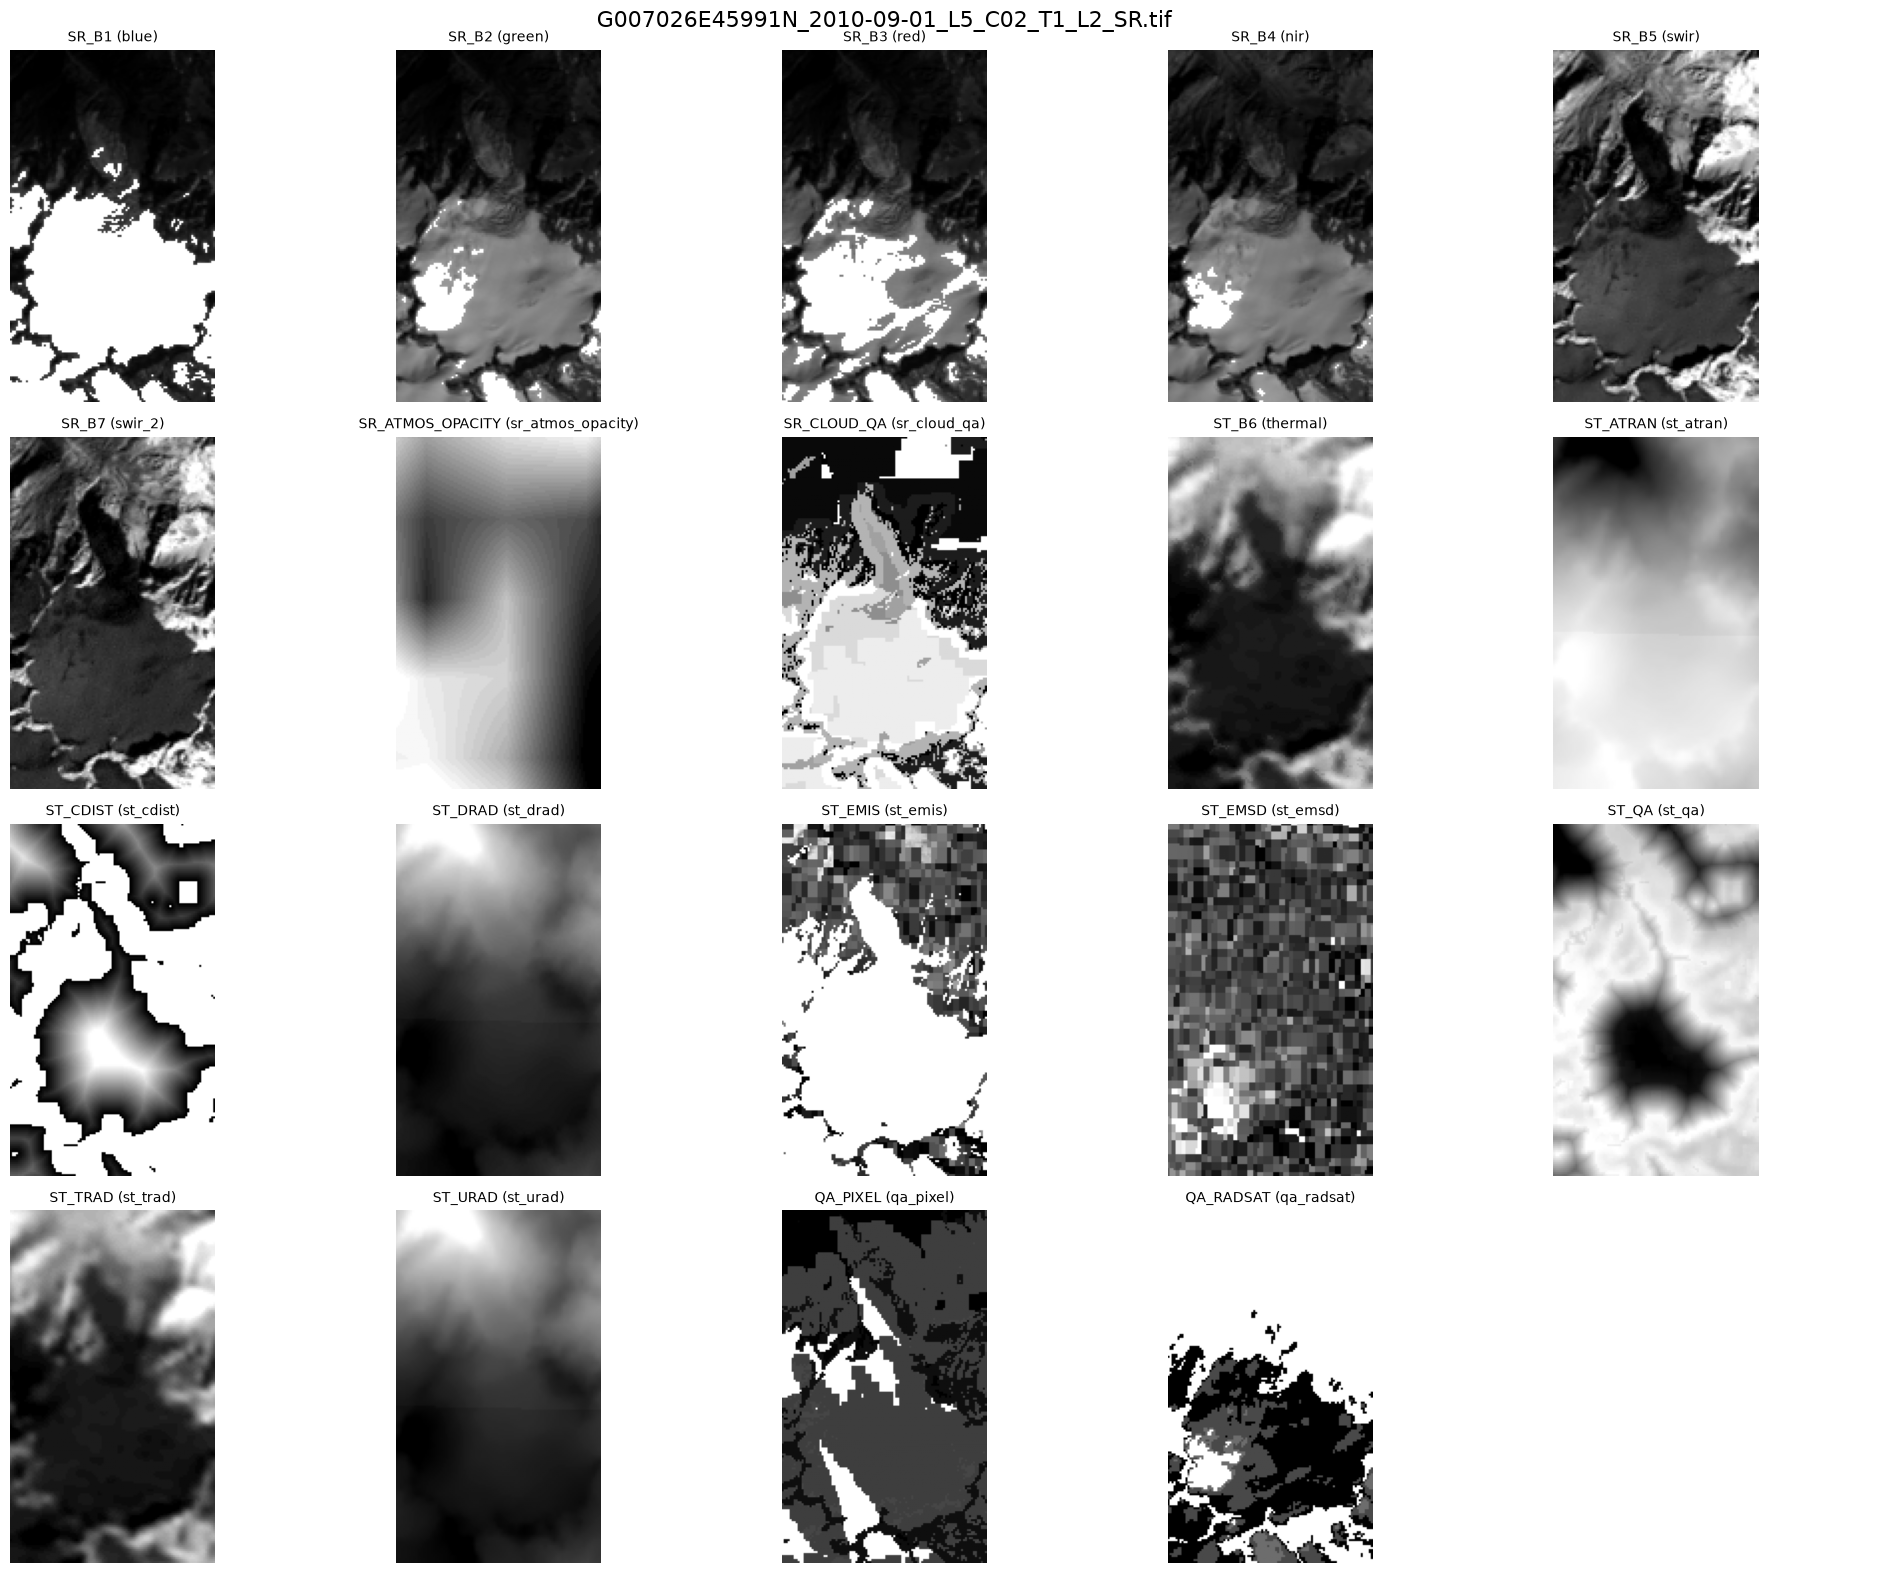

In [3]:
GLIMS_ID = "G007026E45991N"   # Trient
SCENE = None                  # a file name, or None for the glacier's middle scene

scenes = scene_paths(landsat / GLIMS_ID)
if not scenes:
    raise ValueError(f"{GLIMS_ID} has no scenes{' that pass the filter' if filter_csv else ''}")
print(f"{GLIMS_ID}: {len(scenes)} scenes{' pass the filter' if filter_csv else ''}")
path = landsat / GLIMS_ID / SCENE if SCENE else scenes[len(scenes) // 2]
scene, satellite = read_scene(path)

fig, axs = plt.subplots(4, 5, figsize=(20, 16))
fig.suptitle(path.name, fontsize=16)
names = list(bands.landsat_bands[satellite])
for ax, band, name, ee_id in zip(axs.flat, scene, names, bands.EE_BANDS[satellite], strict=False):
    valid = band[band > 0]
    low, high = np.percentile(valid, [2, 98]) if valid.size else (0, 1)
    ax.imshow(np.ma.masked_less_equal(band, 0), cmap="gray", vmin=low, vmax=high)
    ax.set_facecolor("black")
    ax.set_title(f"{ee_id} ({name})", fontsize=10)
    ax.axis("off")
axs.flat[-1].axis("off")
fig.tight_layout()
plt.show()

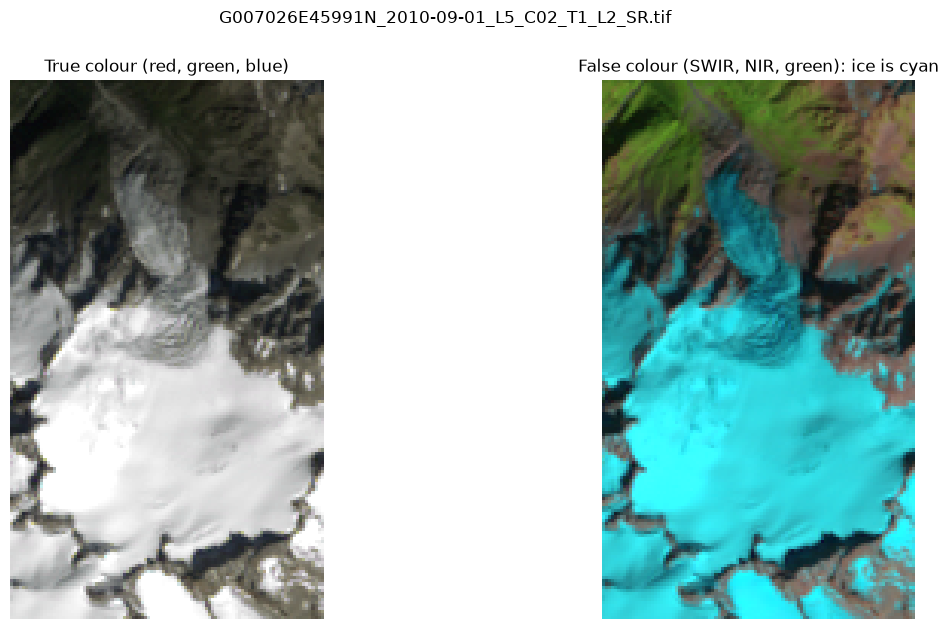

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 7))
axs[0].imshow(true_colour(scene, satellite))
axs[0].set_title("True colour (red, green, blue)")
axs[1].imshow(false_colour(scene, satellite))
axs[1].set_title("False colour (SWIR, NIR, green): ice is cyan")
for ax in axs:
    ax.axis("off")
fig.suptitle(path.name)
plt.show()

## True colour across glaciers

98 glaciers with a scene that passes the filter


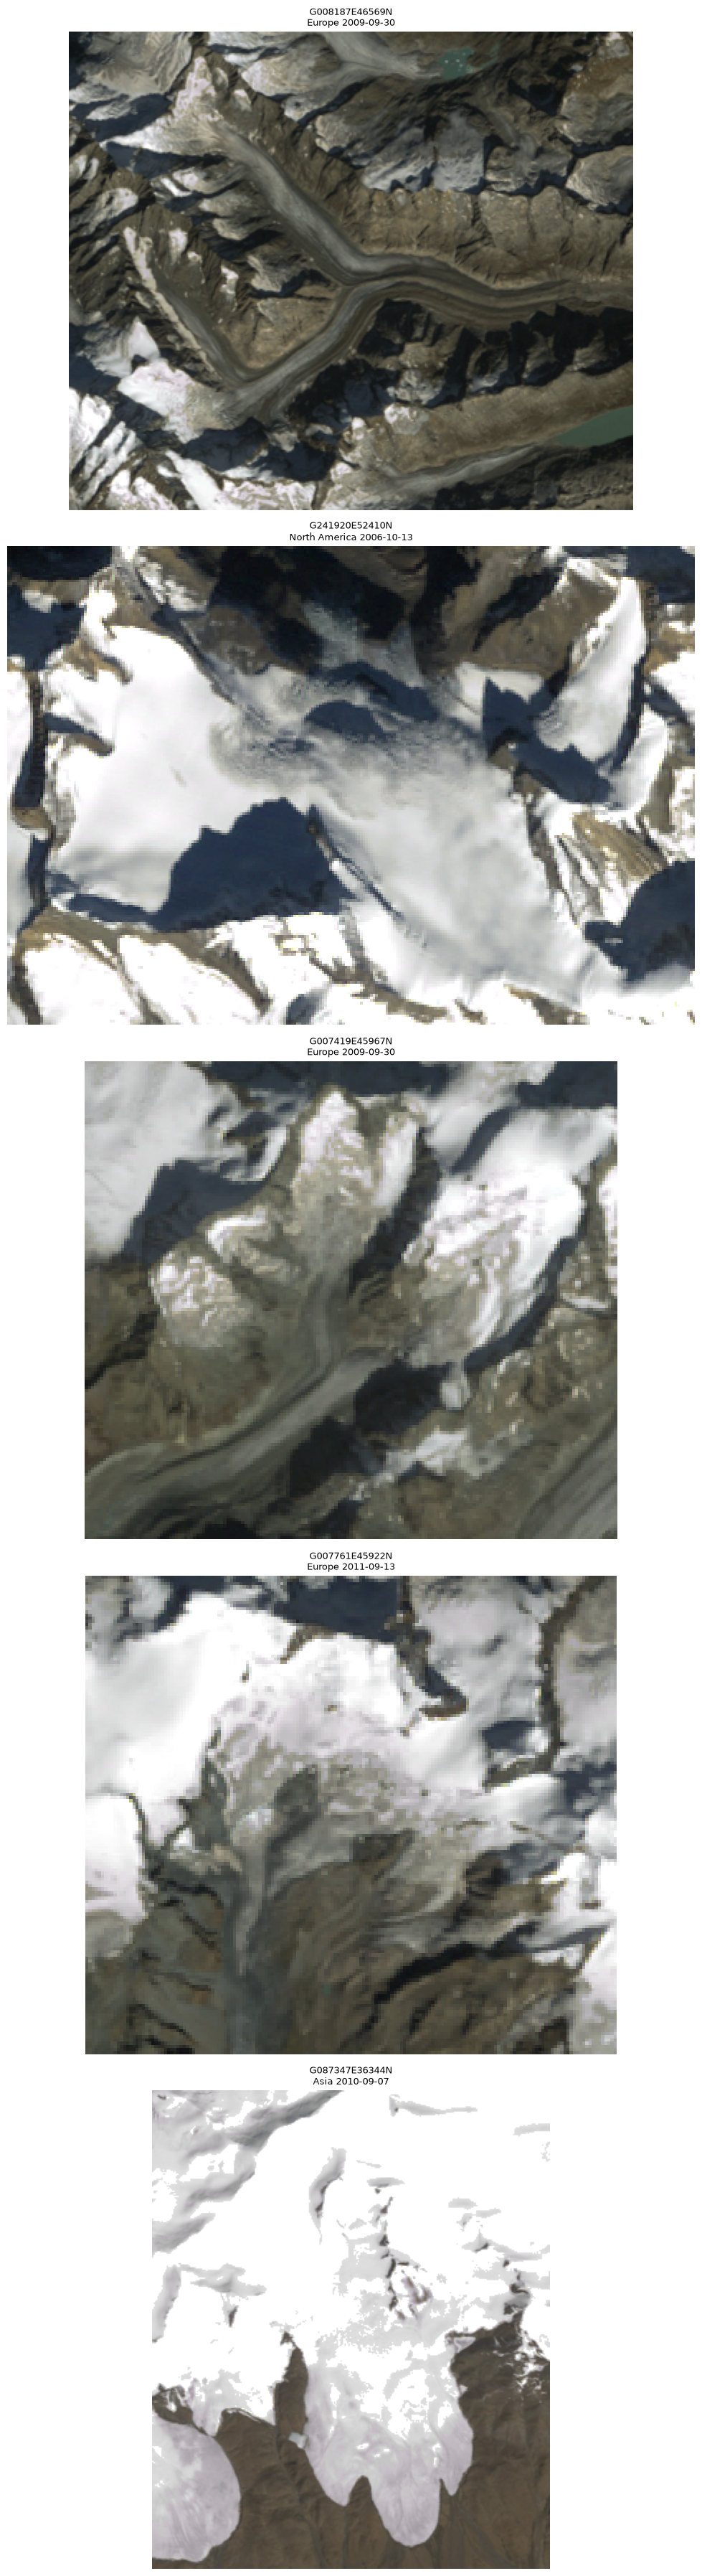

In [6]:
N_GLACIERS = 9

if filter_csv:  # the filter names its glaciers; avoids listing every directory
    listed = pd.read_csv(filter_csv, usecols=["glims_id"])["glims_id"].unique()
    glaciers = sorted(landsat / g for g in listed if (landsat / g).is_dir())
else:
    glaciers = sorted(p for p in landsat.iterdir() if p.is_dir())
glaciers = [g for g in glaciers if scene_paths(g)]
print(f"{len(glaciers)} glaciers{' with a scene that passes the filter' if filter_csv else ''}")
rng = np.random.default_rng(3)
picks = rng.choice(len(glaciers), min(N_GLACIERS, len(glaciers)), replace=False)
picked = [glaciers[i] for i in picks]
region = (pd.read_csv(config.SAMPLE_INFERENCE_ROOT / "glaciers.csv").set_index("glims_id")["region"]
          if USE_SAMPLE else pd.Series(dtype=str))

rows = int(np.ceil(len(picked) / 2))
fig, axs = plt.subplots(rows, 1, figsize=(40, 7.2 * rows))
for ax in axs.flat:
    ax.axis("off")
for ax, glacier in zip(axs.flat, picked, strict=False):
    path = scene_paths(glacier)[0]
    scene, satellite = read_scene(path)
    ax.imshow(true_colour(scene, satellite))
    date = path.name.split('_')[1]
    ax.set_title(f"{glacier.name}\n{region.get(glacier.name, '')} {date}", fontsize=9)
fig.tight_layout()
plt.show()

## One glacier over time

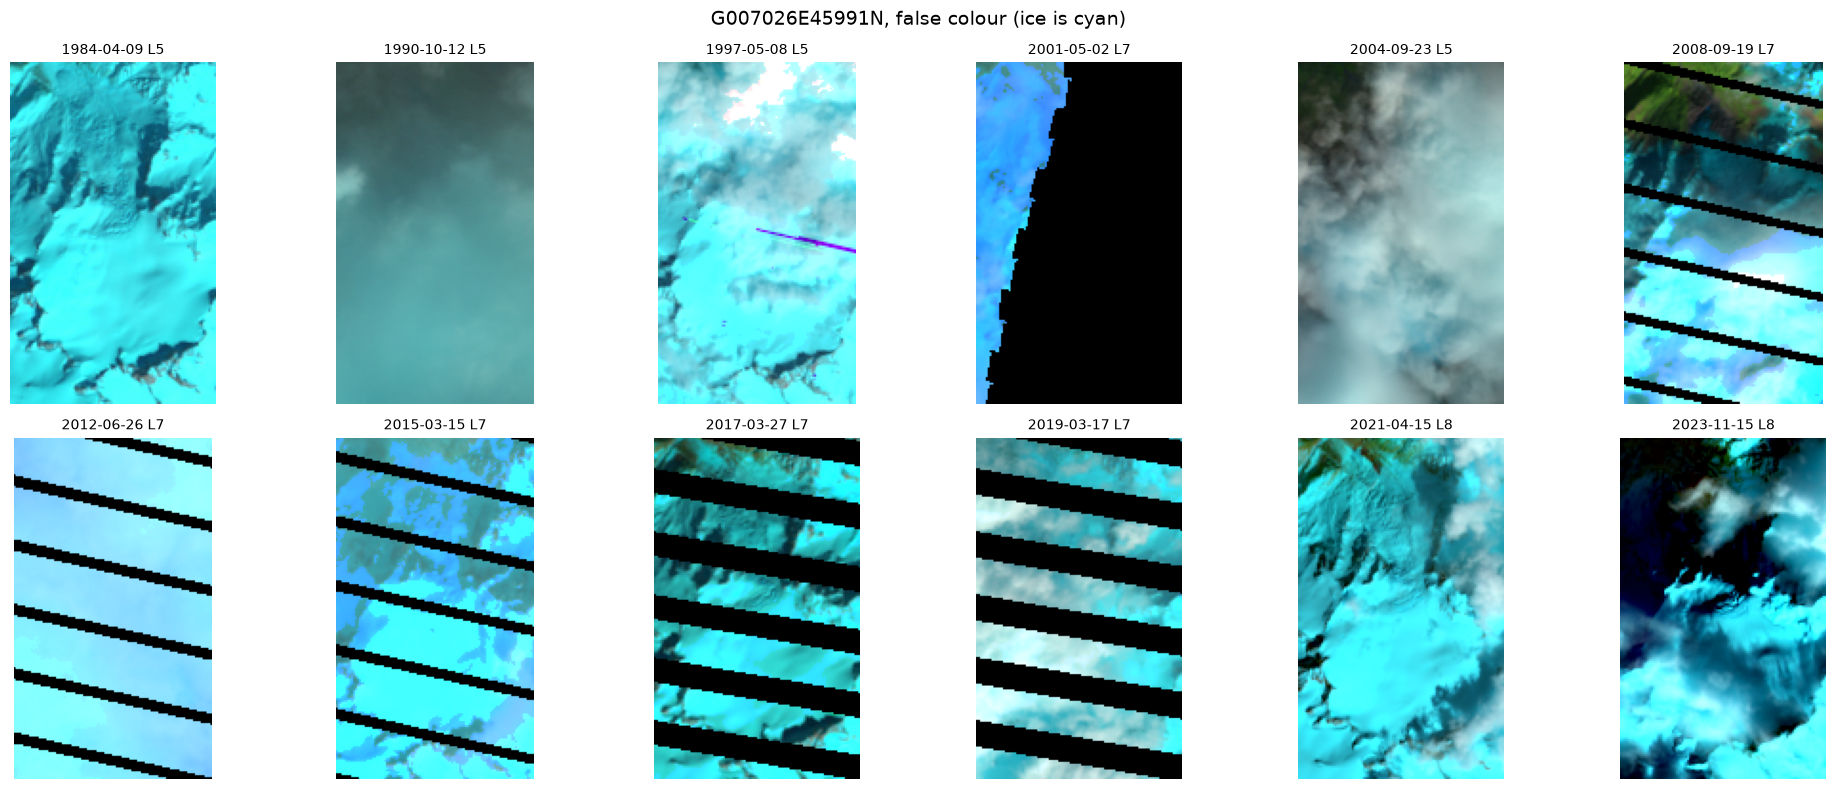

In [34]:
N_FRAMES = 12

steps = np.linspace(0, len(scenes) - 1, min(N_FRAMES, len(scenes))).astype(int)
frames = [scenes[i] for i in steps]
fig, axs = plt.subplots(2, int(np.ceil(len(frames) / 2)), figsize=(20, 8))
for ax in axs.flat:
    ax.axis("off")
for ax, path in zip(axs.flat, frames, strict=False):
    scene, satellite = read_scene(path)
    ax.imshow(false_colour(scene, satellite))
    ax.set_title(f"{path.name.split('_')[1]} {path.name.split('_')[2]}", fontsize=10)
fig.suptitle(f"{GLIMS_ID}, false colour (ice is cyan)", fontsize=14)
fig.tight_layout()
plt.show()